# MATPLOTLIB MASTERY — NOTEBOOK 2
## Chapters 6–15: Legends → Colors → Styles/rcParams → Markers/Linestyles → Axis Limits → Ticks → Grid/Spines → Scatter → Bubble Charts → Bar Charts

Continuing directly from Notebook 1. Run all cells in order.

### Progress Tracker (this notebook)
- [x] Chapter 6 — Legends
- [x] Chapter 7 — Colors
- [x] Chapter 8 — Styles / rcParams
- [x] Chapter 9 — Markers and Line Styles
- [x] Chapter 10 — Axis Limits
- [x] Chapter 11 — Ticks
- [x] Chapter 12 — Gridlines and Spines
- [x] Chapter 13 — Scatter Plots
- [x] Chapter 14 — Bubble Charts
- [x] Chapter 15 — Bar Charts


In [ ]:
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
np.random.seed(42)


---
# CHAPTER 6 — LEGENDS

## 1. Concept
`ax.legend()` scans every Artist in the Axes that has a non-`None` `label`, and draws a box mapping each visual style (color/marker/linestyle) to its text description.

## 2. Why It Matters
A chart with 2+ series and **no legend** forces the reader to guess which line is which — a common, easily-avoidable defect. But an **over-used** legend (too large, covering data, or listing 15 items) can hurt readability more than it helps — legends are a tool to place deliberately, not a default to always add.

## 3–4. NumPy / Pandas Connection
Legends operate purely on labeled Artists, so no direct NumPy/Pandas linkage — but the `label=` string is often built dynamically from a Pandas column name or group key, e.g. `label=f"Region: {region}"` inside a `for region, group in df.groupby("region")` loop (used heavily in EDA).

## 5. Industry Use Case
Model comparison charts (one line per model), regional/segment breakdowns, and any chart with more than one series.


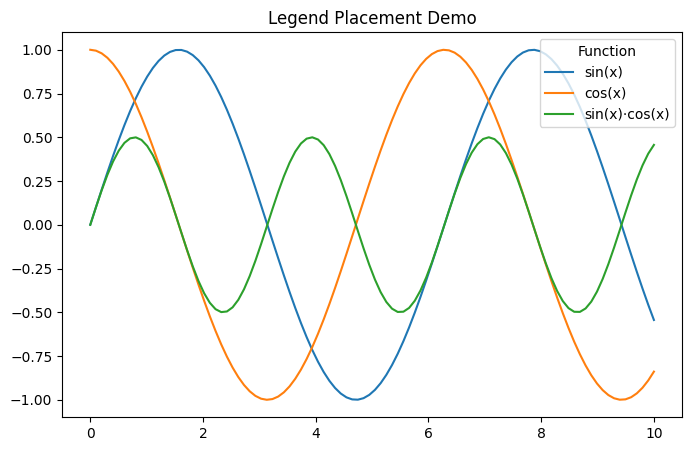

In [ ]:
x = np.linspace(0, 10, 100)

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(x, np.sin(x), label="sin(x)")
ax.plot(x, np.cos(x), label="cos(x)")
ax.plot(x, np.sin(x) * np.cos(x), label="sin(x)·cos(x)")

ax.legend(
    loc="upper right",       # anchor position within the axes
    fontsize=10,
    title="Function",
    frameon=True,            # draw the box border
    ncol=1,                  # number of columns in the legend
)
ax.set_title("Legend Placement Demo")
plt.show()


### Parameter Explanation
| Parameter | Meaning |
|---|---|
| `loc` | Position: `'best'`, `'upper right'`, `'lower left'`, `'center'`, etc. `'best'` (default) tries to avoid covering data but is slower and imperfect |
| `bbox_to_anchor` | Precise placement **outside** the axes, e.g. `(1.05, 1)` to push the legend fully to the right of the plot |
| `fontsize` | Text size |
| `title` | Optional heading for the legend box |
| `frameon` | Whether to draw a border/background box |
| `ncol` | Arrange legend entries into multiple columns (useful for many series) |

### Placing a Legend Outside the Plot (common in dashboards with many series)


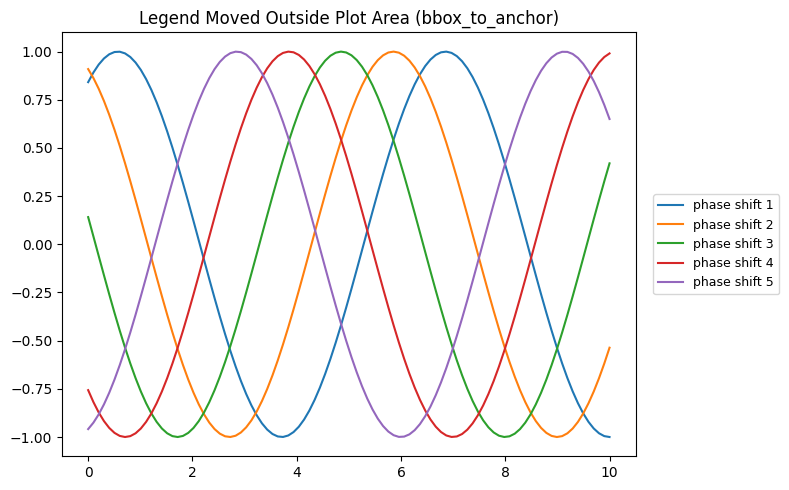

In [ ]:
fig, ax = plt.subplots(figsize=(8, 5))
for k in range(1, 6):
    ax.plot(x, np.sin(x + k), label=f"phase shift {k}")

ax.legend(loc="center left", bbox_to_anchor=(1.02, 0.5), fontsize=9)
ax.set_title("Legend Moved Outside Plot Area (bbox_to_anchor)")
plt.tight_layout()
plt.show()


### Internal Working
`ax.legend()` builds a `Legend` Artist by querying `ax.get_legend_handles_labels()`, which walks `ax.lines`, `ax.patches`, `ax.collections`, etc., collecting `(handle, label)` pairs for anything with a set label.

### Interpretation
When series count grows past ~6–8, a legend stops being efficiently scannable — this is the trigger to switch to **direct labeling** (placing text right next to each line's endpoint) or **small multiples** (Chapter 28/73) instead.

### Common Mistakes
- Calling `.legend()` with no labeled artists → empty or warning-triggering legend.
- Default `loc='best'` silently covering important data — always sanity-check placement visually.
- Too many series crammed into one legend, making colors indistinguishable.

### Debugging
If the legend doesn't appear: confirm at least one `plot()`/`bar()`/`scatter()` call actually passed `label=`, and that `ax.legend()` is called **after** those plotting calls (order matters — it only sees artists that exist at call time, though re-calling `.legend()` refreshes it).

### Best Practices
- Use `bbox_to_anchor` to move dense legends outside the plotting area rather than shrinking font size to fit.
- Consider direct line-end labeling instead of a legend when there are very few (2–3) series — often cleaner.

### Interview Insight
**Q: When does a legend become harmful rather than helpful?**
A: When it has so many entries, or such similar colors, that matching a line to its label takes longer than reading a plain data table would — at that point, small multiples or direct labeling communicate faster.

### Mini Exercise
Recreate the 5-phase-shift plot with `ncol=2` inside the legend box (keep `loc='best'`, remove `bbox_to_anchor`) and observe the layout change.

### Quiz (Chapter 6)
1. What does `ax.legend()` actually query to build its contents?
2. When should you avoid using a legend altogether?
3. What's the purpose of `bbox_to_anchor`?


---
# CHAPTER 7 — COLORS

## 1. Concept
Matplotlib accepts color in several equivalent forms: named strings (`"red"`, `"tab:blue"`), hex (`"#1f77b4"`), and RGB/RGBA tuples with values in `[0, 1]` (`(0.2, 0.5, 0.8)` or `(0.2, 0.5, 0.8, 0.5)` for semi-transparent).

## 2. Why It Matters
Color is not decoration — it is an **encoding channel**, exactly like position or size. Choosing the wrong color scheme actively misleads:
- Using a **sequential** colormap (light→dark) for categorical, unordered groups implies a false ranking.
- Using a **diverging** colormap (two hues meeting at a neutral midpoint) for data with no meaningful "zero" or midpoint is confusing.
- Ignoring colorblindness (~8% of men) can make a chart unreadable for a meaningful fraction of your audience.

## 3–4. NumPy / Pandas Connection
When you pass `c=some_array` to `ax.scatter()`, Matplotlib maps each numeric value through a **colormap** — this is a direct NumPy-array-to-color pipeline (detailed further in Chapter 13).

## 5. Industry Use Case
- **Categorical/qualitative** palette: distinct product lines, regions, model names.
- **Sequential** palette: a single quantity from low to high (e.g., density, probability).
- **Diverging** palette: values relative to a meaningful zero (e.g., profit/loss, correlation coefficients from -1 to 1).


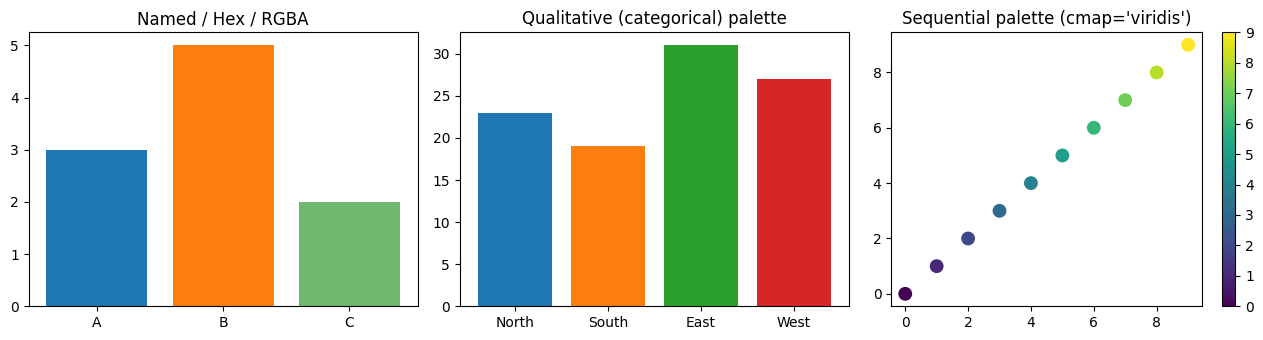

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))

# Named / hex / RGBA forms all valid
axes[0].bar(["A", "B", "C"], [3, 5, 2], color=["tab:blue", "#ff7f0e", (0.2, 0.6, 0.2, 0.7)])
axes[0].set_title("Named / Hex / RGBA")

# Qualitative palette for unordered categories
cats = ["North", "South", "East", "West"]
vals = [23, 19, 31, 27]
axes[1].bar(cats, vals, color=plt.cm.tab10.colors[:4])
axes[1].set_title("Qualitative (categorical) palette")

# Sequential palette mapped from a numeric array
data = np.arange(10)
sc = axes[2].scatter(data, data, c=data, cmap="viridis", s=80)
axes[2].set_title("Sequential palette (cmap='viridis')")
fig.colorbar(sc, ax=axes[2])

plt.tight_layout()
plt.show()


### Parameter / Concept Explanation
| Concept | Use case | Example cmap |
|---|---|---|
| Sequential | One variable, low→high, no natural midpoint | `viridis`, `plasma`, `Blues` |
| Diverging | Values around a meaningful center (0, average) | `coolwarm`, `RdBu`, `PiYG` |
| Qualitative | Unordered categories | `tab10`, `Set2`, `Accent` |

### Colorblind-Friendly Practice
- `viridis` (Matplotlib's default sequential colormap since v2.0) is explicitly designed to be perceptually uniform and colorblind-safe — prefer it over the old `jet` colormap, which is both perceptually distorting and inaccessible.
- Never rely on **red vs green alone** to distinguish two categories (the single most common colorblind confusion); pair color with a second channel (linestyle, marker shape, or direct labels).

### Internal Working
A colormap (`plt.cm.viridis`) is a lookup function: it takes a float in `[0, 1]` and returns an RGBA tuple. When you pass `c=data` to `scatter()`, Matplotlib first **normalizes** `data` to `[0, 1]` (via a `Normalize` object, default linear min→max) before looking up colors — this is why outliers can compress the visible color range for the rest of the data (a common `imshow`/heatmap gotcha revisited in Chapter 46).

### Common Mistakes
- Using `jet` (rainbow) colormap for scientific/EDA plots — it's perceptually non-uniform (introduces fake visual "boundaries" in continuous data) and not colorblind-safe.
- Using a sequential colormap for categorical data (implies false order).
- Relying purely on hue with no legend or colorbar to explain what the colors mean.

### Best Practices
- Sequential data → `viridis`/`plasma`. Diverging data → `coolwarm`/`RdBu`. Categories → `tab10`/`Set2`.
- Always include a colorbar (Chapter 48) whenever color encodes a continuous variable.

### Interview Insight
**Q: Why might a rainbow ("jet") colormap mislead an analyst?**
A: `jet` is not perceptually uniform — equal steps in data value do not correspond to equal perceived changes in color, which can create the illusion of sharp boundaries or features that don't exist in the underlying data. `viridis` was adopted as Matplotlib's default specifically to fix this.

### Mini Exercise
Re-plot the sequential scatter example using `cmap="coolwarm"` on data ranging from -5 to 5 (so zero sits at the diverging midpoint) and compare interpretability to `viridis` on the same data.

### Quiz (Chapter 7)
1. Name the three colormap categories and when each is appropriate.
2. Why is `viridis` generally preferred over `jet`?
3. What does `Normalize` do before a colormap is applied?


---
# CHAPTER 8 — STYLES AND rcParams

## 1. Concept
`plt.style.use(name)` applies a bundle of preset defaults (colors, fonts, gridlines, backgrounds) to **all subsequent plots** in the session. `plt.rcParams` is the underlying dictionary of every default Matplotlib setting — styles are just pre-packaged `rcParams` overrides.

## 2. Why It Matters
Setting a **consistent style once** at the top of a notebook/project guarantees every chart in a report looks cohesive, instead of manually re-styling each figure — a huge time saver and a professional-polish signal.


Available styles (sample): ['Solarize_Light2', '_classic_test_patch', '_mpl-gallery', '_mpl-gallery-nogrid', 'bmh', 'classic', 'dark_background', 'fast']


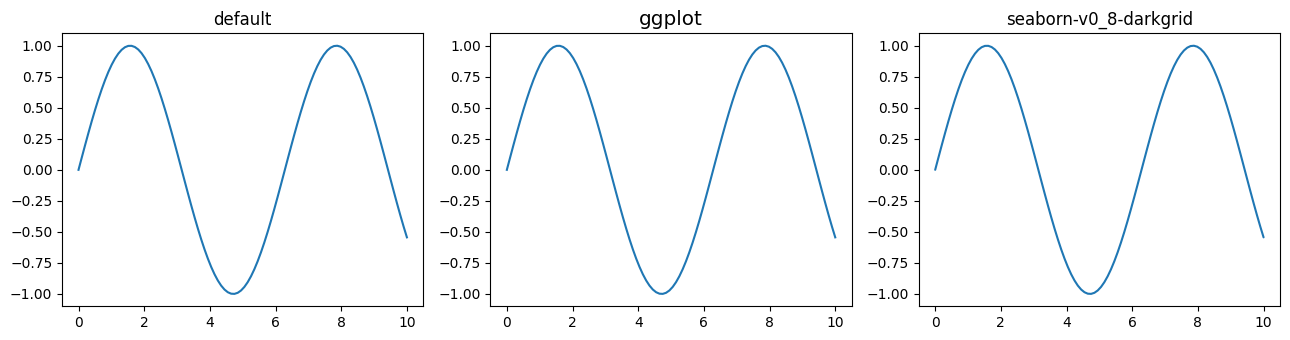

In [ ]:
print("Available styles (sample):", plt.style.available[:8])

fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
x = np.linspace(0, 10, 100)

for ax, style in zip(axes, ["default", "ggplot", "seaborn-v0_8-darkgrid"]):
    with plt.style.context(style):
        ax.plot(x, np.sin(x))
        ax.set_title(style)

plt.tight_layout()
plt.show()


### Key APIs
- `plt.style.use("ggplot")` — applies globally for the rest of the session (persists until changed).
- `with plt.style.context("ggplot"): ...` — applies **only within the `with` block**, then reverts. Preferred in notebooks/functions to avoid unexpected side-effects on later cells.
- `plt.rcParams["lines.linewidth"] = 2` — override one specific setting directly, permanently for the session (or until reset).
- `plt.rcParams.update({...})` — batch-override many settings at once (common at the top of a project notebook).

### Project-Level Consistent Style Example


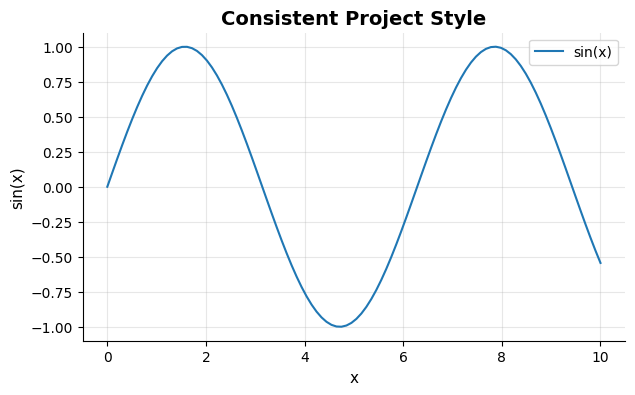

In [ ]:
project_style = {
    "figure.figsize": (7, 4),
    "axes.titlesize": 14,
    "axes.titleweight": "bold",
    "axes.labelsize": 11,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "font.size": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
}

with plt.rc_context(project_style):
    fig, ax = plt.subplots()
    ax.plot(x, np.sin(x), label="sin(x)")
    ax.set_title("Consistent Project Style")
    ax.set_xlabel("x")
    ax.set_ylabel("sin(x)")
    ax.legend()
    plt.show()


### Internal Working
`rcParams` is a global dictionary-like object consulted every time an Artist is created without an explicit override — e.g., `ax.plot()` without a `color=` argument pulls the next color from `rcParams["axes.prop_cycle"]`. Styles are literally `.mplstyle` text files listing `key: value` pairs — you can write your own and load it with `plt.style.use("/path/to/mystyle.mplstyle")`.

### Common Mistakes
- Calling `plt.style.use()` (global, persistent) inside a function meant to be reusable — it silently changes style for every subsequent plot in the notebook. Use `plt.style.context()` or `plt.rc_context()` instead inside functions.
- Forgetting that some third-party styles (`seaborn-*`) may be renamed/removed between Matplotlib versions — always check `plt.style.available`.

### Best Practices
- Define one project-wide `rcParams` dict (or a `.mplstyle` file) at the start of a project/notebook and apply it once.
- Prefer the `with` context-manager forms inside reusable functions to avoid global side effects.

### Interview Insight
**Q: What's the difference between `plt.style.use()` and `plt.rcParams.update()`?**
A: `plt.style.use()` swaps in an entire named bundle of pre-defined settings; `plt.rcParams.update()` lets you override specific individual settings directly, and can be layered on top of a style.

### Mini Exercise
Create your own style dict with a non-default `figure.figsize` and `axes.grid=True`, apply it via `plt.rc_context()`, and confirm the change doesn't persist to a plot made outside the `with` block.

### Quiz (Chapter 8)
1. What's the risk of calling `plt.style.use()` inside a shared/reusable function?
2. What's stored in `rcParams["axes.prop_cycle"]`?
3. How would you apply a style temporarily, for one plot only?


---
# CHAPTER 9 — MARKERS AND LINE STYLES

## 1–2. Concept & Why It Matters
Beyond color, **marker shape** and **line style** are additional encoding channels — critical when a chart may be printed in grayscale, viewed by a colorblind reader, or simply needs a third dimension of distinction beyond color and position.

## Reference Table
| Linestyle | Code | When to use |
|---|---|---|
| Solid | `'-'` | Default; primary series |
| Dashed | `'--'` | Secondary series, forecasts/projections |
| Dotted | `':'` | Reference lines, thresholds |
| Dash-dot | `'-.'` | Tertiary series |

| Marker | Code | Notes |
|---|---|---|
| Circle | `'o'` | Most common general-purpose marker |
| Square | `'s'` | |
| Triangle up | `'^'` | |
| X | `'x'` | Good for "error" or "excluded" points |
| Plus | `'+'` | |
| Diamond | `'D'` | |


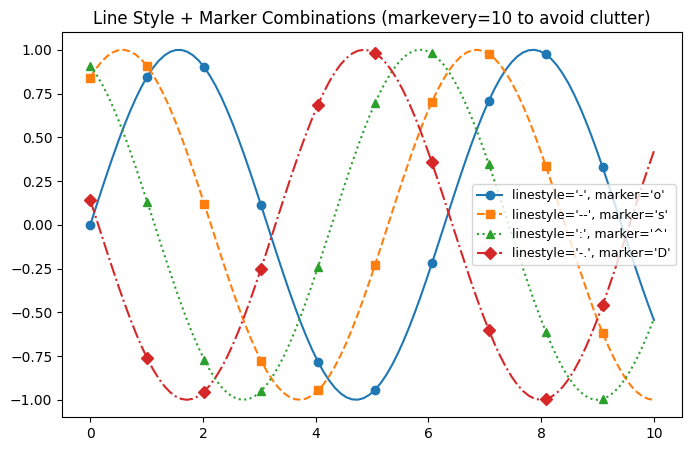

In [ ]:
fig, ax = plt.subplots(figsize=(8, 5))
styles = [("-", "o"), ("--", "s"), (":", "^"), ("-.", "D")]
for i, (ls, mk) in enumerate(styles):
    ax.plot(x, np.sin(x + i), linestyle=ls, marker=mk, markevery=10,
             label=f"linestyle={ls!r}, marker={mk!r}")

ax.legend(fontsize=9)
ax.set_title("Line Style + Marker Combinations (markevery=10 to avoid clutter)")
plt.show()


### Parameter Explanation
- `markevery=10` — only draws a marker every 10th data point, avoiding clutter on dense data while still using linestyle to distinguish full curves. This is the standard fix for "too many markers" (a Chapter 75 debugging scenario).
- Forecast convention: solid line = observed/historical, dashed line = forecast/projection — a very common, easily-recognized visual grammar in business reporting.

### Common Mistakes
- Using markers on a line with 1,000+ points — unreadable and slow (fix: `markevery` or drop markers entirely).
- Relying on linestyle alone for many (5+) series — dashed vs dash-dot vs dotted become hard to tell apart quickly; combine with color for anything beyond 3–4 series.

### Best Practices
- Reserve distinctive marker shapes for genuinely important series (e.g., "our model" vs "baselines").
- Use the solid/dashed convention for historical vs projected data — readers recognize it without an explanation.

### Interview Insight
**Q: You have 8 time series to plot on one chart. How do you keep it readable?**
A: Combine at most 2 encoding channels (color + linestyle, or color + marker) rather than relying on one; beyond ~6 series even that struggles, so switch to small multiples (separate subplots) or an interactive alternative instead of cramming everything onto one Axes.

### Mini Exercise
Recreate the 4-series plot without `markevery` and observe how cluttered it becomes — then apply `markevery=5` and compare.

### Quiz (Chapter 9)
1. What does `markevery` solve, and when should you use it?
2. What's the conventional linestyle grammar for historical vs. forecast data?
3. Beyond how many series should you generally abandon a single combined-encoding chart in favor of small multiples?


---
# CHAPTER 10 — AXIS LIMITS

## 1. Concept
`ax.set_xlim(min, max)` / `ax.set_ylim(min, max)` override Matplotlib's automatic data-driven limits. By default, Matplotlib autoscales to fit all plotted data with a small margin.

## 2. Why It Matters
Axis limits are one of the most common sources of **misleading visualization** (fully covered in Chapter 79):
- **Truncated y-axis** (not starting at zero) on a bar chart can make a 2% difference look like a 200% difference.
- Zooming (`set_xlim`) can be legitimate for detail inspection, or can be used to **hide inconvenient data** outside the visible window — the same technique, opposite intent.

## 3–4. NumPy / Pandas Connection
Limits are frequently set from computed statistics: `ax.set_ylim(0, df["value"].max() * 1.1)` — a 10% headroom pattern very common in production dashboard code.


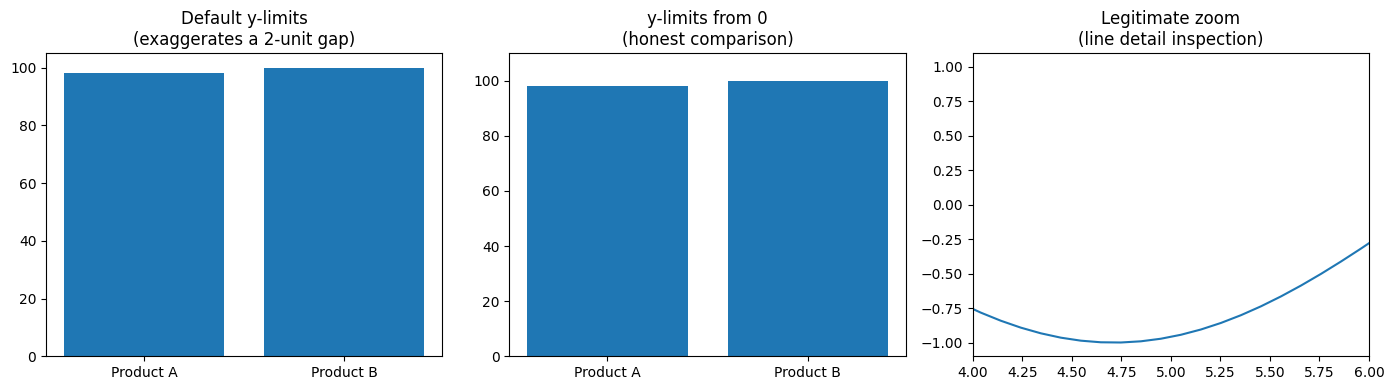

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

categories = ["Product A", "Product B"]
values = [98, 100]

# Panel 1: default (truncated) autoscale on a bar chart — DANGEROUS
axes[0].bar(categories, values, color="tab:blue")
axes[0].set_title("Default y-limits\n(exaggerates a 2-unit gap)")

# Panel 2: correctly zero-based bar chart
axes[1].bar(categories, values, color="tab:blue")
axes[1].set_ylim(0, 110)
axes[1].set_title("y-limits from 0\n(honest comparison)")

# Panel 3: legitimate zoom on a LINE chart (not a bar chart) to inspect detail
axes[2].plot(x, np.sin(x))
axes[2].set_xlim(4, 6)
axes[2].set_title("Legitimate zoom\n(line detail inspection)")

plt.tight_layout()
plt.show()


### Interpretation
Panel 1's default autoscale makes a 2-unit difference (98 vs 100 — a ~2% gap) look enormous because the bars nearly fill the entire visible range. Panel 2, with `ylim` forced to start at 0, honestly shows the bars as nearly identical height — the correct representation for a **bar chart**, where bar *length* is the reader's implicit visual cue for magnitude.

### The Rule, Precisely
- **Bar charts**: y-axis (or x-axis for `barh`) should almost always start at **zero**, because length encodes magnitude and a non-zero baseline breaks that encoding.
- **Line charts**: a non-zero, zoomed y-axis is often legitimate and useful — because a line's *slope/shape*, not its distance from an arbitrary baseline, is what's being read. Just label it clearly so the zoom is transparent, not hidden.

### Common Mistakes
- Truncating a bar chart's y-axis to "make differences look bigger" for a favorable narrative — this is a classic manipulative visualization pattern (Chapter 79).
- Forgetting `ax.set_xlim()`/`set_ylim()` can also **exclude** outliers from view unintentionally, silently distorting a distribution plot.

### Debugging
If your plot appears blank or has one giant flat line, check `ax.get_xlim()`/`get_ylim()` — a stray very-large or very-small value elsewhere in your array can be forcing the autoscale to an unhelpful range; this is a very common histogram/scatter debugging step (Chapter 75).

### Best Practices
- Default to zero-baseline for bar charts, always.
- For line charts, zoom deliberately and say so in the title/caption if the full range would tell a materially different story.

### Interview Insight
**Q: A bar chart shows Product A at 98 and Product B at 100, with the y-axis running from 90 to 100. What's wrong, and how do you fix it?**
A: The truncated y-axis makes a ~2% difference look dramatic because it isn't anchored at zero, which is what a bar's length is implicitly compared against. Fix: `ax.set_ylim(0, ...)`, or use a line/dot plot if the intent is genuinely to show a small, real difference precisely.

### Mini Exercise
Take any bar chart you've built so far and check: does its y-axis start at zero? If not, fix it and compare the visual impression before/after.

### Quiz (Chapter 10)
1. Why is a non-zero baseline dangerous specifically for bar charts but often fine for line charts?
2. What's a legitimate reason to call `ax.set_xlim()` on a line chart?
3. How can axis limits accidentally hide outliers?


---
# CHAPTER 11 — TICKS

## 1. Concept
Ticks are the marked reference points along an axis; each tick has a **position** and a **label**. Matplotlib auto-generates "nice" tick positions by default, but production code frequently needs explicit control — currency formatting, percentage formatting, date formatting, or simply thinning out overcrowded labels.

## 2. Why It Matters
Poor tick formatting (e.g., `1000000` instead of `$1.0M`, or overlapping rotated date labels) is one of the most common "amateur notebook" tells versus a polished, professional chart.


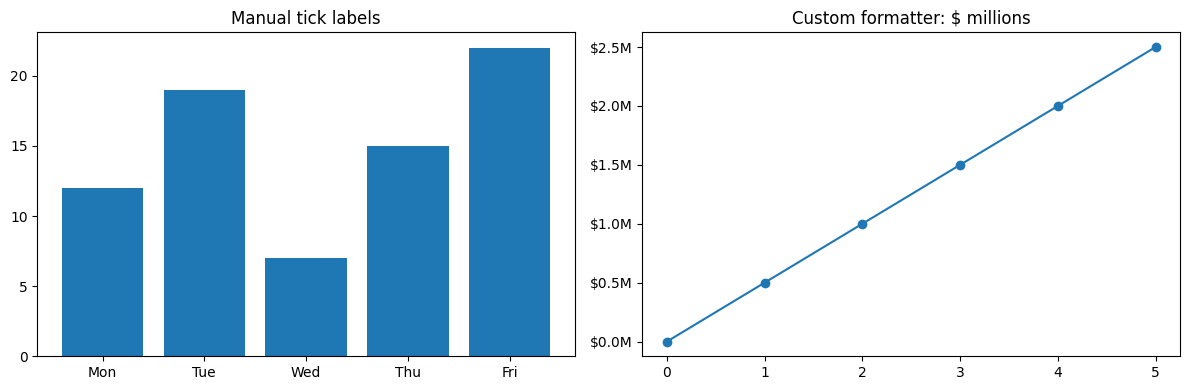

In [ ]:
from matplotlib.ticker import FuncFormatter, MultipleLocator

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# --- Manual tick positions/labels ---
categories_x = np.arange(5)
axes[0].bar(categories_x, [12, 19, 7, 15, 22])
axes[0].set_xticks(categories_x)
axes[0].set_xticklabels(["Mon", "Tue", "Wed", "Thu", "Fri"], rotation=0)
axes[0].set_title("Manual tick labels")

# --- Custom formatter: raw numbers -> currency ---
revenue = np.linspace(0, 2_500_000, 6)
axes[1].plot(revenue, marker="o")
axes[1].yaxis.set_major_formatter(FuncFormatter(lambda val, pos: f"${val/1e6:.1f}M"))
axes[1].set_title("Custom formatter: $ millions")

plt.tight_layout()
plt.show()


### Parameter / API Explanation
- `ax.set_xticks(positions)` — sets **where** ticks appear (in data coordinates).
- `ax.set_xticklabels(labels)` — sets what **text** appears at those positions (must match length/order of `set_xticks`).
- `ax.tick_params(axis='x', rotation=45)` — rotate tick labels (essential for long category names or dates to prevent overlap).
- `matplotlib.ticker.FuncFormatter(func)` — the professional way to format numeric ticks (currency, percentages, abbreviated large numbers) without manually converting the underlying data.
- `matplotlib.ticker.MultipleLocator(n)` — forces ticks at every multiple of `n`, useful for controlling density precisely.

### Common Mistakes
- Calling `set_xticklabels()` **without** first calling `set_xticks()` with matching length — mismatched labels silently apply to the wrong positions, or (in recent Matplotlib) raise a `UserWarning`.
- Long/rotated tick labels overlapping each other — fix with `rotation=45, ha='right'` or by reducing tick frequency.
- Manually recomputing a formatted string column in the DataFrame just to plot it, instead of using a `FuncFormatter` — this pollutes your data with presentation logic.

### Best Practices
- Prefer `FuncFormatter`/`PercentFormatter`/`StrMethodFormatter` over hand-editing the underlying data for display purposes — keep data and presentation separated.
- For date axes, prefer Matplotlib's dedicated date locators/formatters (Chapter 38) over manual string ticks.

### Interview Insight
**Q: You need y-axis values displayed as percentages (e.g., 0.25 → "25%") without changing the underlying data. How?**
A: `from matplotlib.ticker import PercentFormatter; ax.yaxis.set_major_formatter(PercentFormatter(xmax=1))` — or a custom `FuncFormatter` — keeping the plotted data as raw fractions while only changing the tick *display*.

### Mini Exercise
Reformat the currency example to show whole dollars with thousands separators (e.g., `$2,500,000`) instead of millions, using `FuncFormatter`.

### Quiz (Chapter 11)
1. What must match in length and order between `set_xticks()` and `set_xticklabels()`?
2. Why prefer a `FuncFormatter` over editing the raw data into pre-formatted strings?
3. When is `rotation=45` on tick labels necessary?


---
# CHAPTER 12 — GRIDLINES AND SPINES

## 1. Concept
- **Gridlines** (`ax.grid()`) are faint reference lines behind the data, helping readers estimate values.
- **Spines** (`ax.spines['top']`, `['right']`, `['left']`, `['bottom']`) are the four border lines framing the Axes.

## 2. Why It Matters
Minimalist design (Edward Tufte's "data-ink ratio" principle, covered fully in Chapter 78) argues that every visual element not carrying information is a small tax on the reader's attention. Removing the top/right spines and using subtle gridlines is a widely recognized professional polish signal.


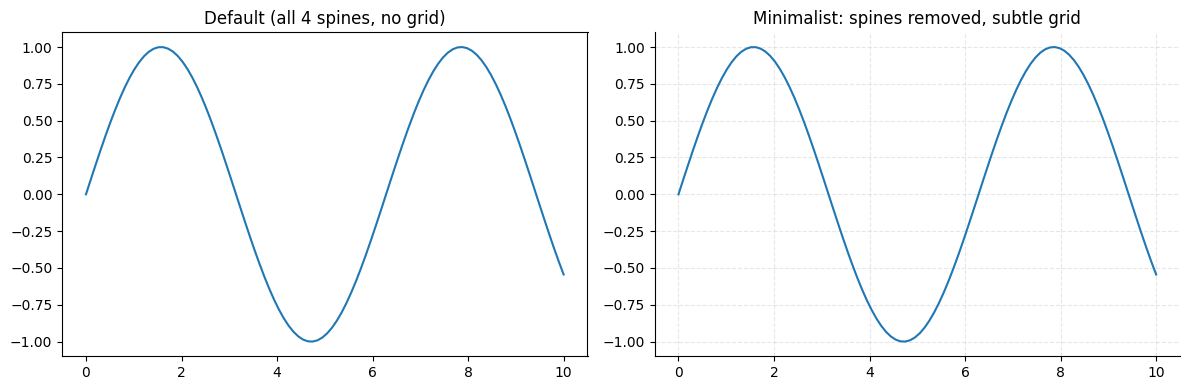

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Default look
axes[0].plot(x, np.sin(x))
axes[0].set_title("Default (all 4 spines, no grid)")

# Minimalist professional look
axes[1].plot(x, np.sin(x), color="tab:blue")
axes[1].spines["top"].set_visible(False)
axes[1].spines["right"].set_visible(False)
axes[1].grid(True, alpha=0.3, linestyle="--")
axes[1].set_title("Minimalist: spines removed, subtle grid")

plt.tight_layout()
plt.show()


### Parameter Explanation
- `ax.grid(True, which='major', axis='both', alpha=0.3, linestyle='--')` — `which` can be `'major'`, `'minor'`, or `'both'`; `axis` can restrict gridlines to `'x'` or `'y'` only; `alpha`/`linestyle` keep gridlines subtle rather than competing with the data.
- `ax.spines['top'].set_visible(False)` — hides one specific border. `ax.spines['left'].set_position(('outward', 10))` — offsets a spine outward (used in more advanced minimalist styles).

### Internal Working
Spines are `Spine` Artist objects (a subclass of `Patch`) stored in the `ax.spines` dict; gridlines are `Line2D` objects drawn at each major/minor tick position, one per axis.

### Common Mistakes
- Heavy, high-contrast gridlines that visually compete with the actual data — always use low `alpha`.
- Leaving all 4 spines on **and** heavy gridlines **and** high-saturation colors simultaneously — visual clutter compounds fast.

### Best Practices
- Default professional look: remove top/right spines, keep bottom/left, use `alpha=0.2–0.4` gridlines on the y-axis only for most charts (x-axis rarely needs grid help since categories/time are usually clear already).

### Interview Insight
**Q: Why do many professional style guides recommend removing the top and right spines?**
A: They carry no information (data is anchored to the bottom/left axes), so removing them reduces visual clutter without any loss of interpretability — a direct application of the "maximize data-ink ratio" principle.

### Mini Exercise
Apply spine removal + subtle gridlines as a reusable pattern via `plt.rc_context()` (Chapter 8) so it can be applied to any chart in one line.

### Quiz (Chapter 12)
1. What Artist type are spines actually instances of?
2. Why use a low `alpha` on gridlines?
3. Which principle motivates removing non-informative spines?


---
# CHAPTER 13 — SCATTER PLOTS

## 1. Concept
`ax.scatter(x, y)` draws independent markers at each (x, y) pair with **no connecting line** — the correct choice when you want to examine the **relationship between two variables** across individual observations, not a trend over an ordered axis.

## 2. Why It Matters
Scatter plots are the primary EDA tool for:
- Detecting correlation/relationship shape (linear, non-linear, none) between two numeric features.
- Spotting outliers and clusters visually before any modeling.
- Visualizing model residuals and actual-vs-predicted comparisons (Chapter 57).

## 3–4. NumPy / Pandas Connection
`ax.scatter(df["feature1"], df["feature2"], c=df["target"], cmap="viridis")` is one of the single most common EDA lines written in any ML notebook — every argument can be a raw Pandas Series.

## 5. Industry Use Case
Feature-vs-feature correlation exploration, feature-vs-target relationships, cluster visualization, model residual analysis.


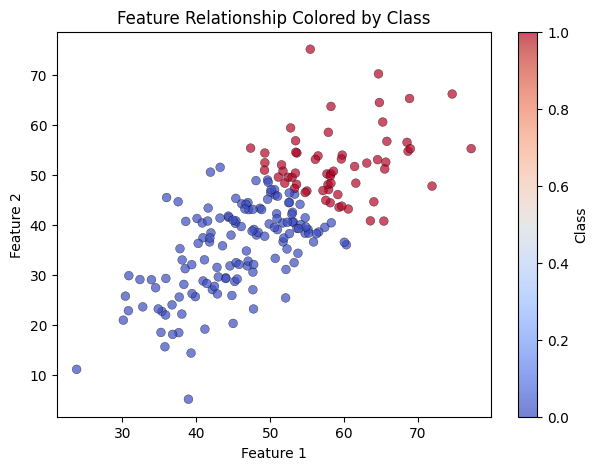

In [ ]:
n = 200
feature1 = np.random.normal(50, 10, n)
feature2 = feature1 * 0.8 + np.random.normal(0, 8, n)   # correlated with noise
target = (feature1 + feature2 > 100).astype(int)         # binary class label

fig, ax = plt.subplots(figsize=(7, 5))
sc = ax.scatter(
    feature1, feature2,
    c=target,             # color encodes the class
    cmap="coolwarm",
    s=40,                 # marker size
    alpha=0.7,
    edgecolors="black",
    linewidths=0.3,
)
ax.set_title("Feature Relationship Colored by Class")
ax.set_xlabel("Feature 1")
ax.set_ylabel("Feature 2")
fig.colorbar(sc, ax=ax, label="Class")
plt.show()


### Parameter Explanation
| Parameter | Meaning |
|---|---|
| `s` | Marker size (points², can be an array for per-point variable size → Chapter 14 bubble charts) |
| `c` | Marker color — a single color, or an array mapped through `cmap` |
| `cmap` | Colormap used when `c` is numeric |
| `alpha` | Transparency — essential when points overlap heavily (overplotting) |
| `edgecolors` / `linewidths` | Marker border — improves contrast against busy backgrounds |
| `marker` | Shape (default circle) |

### Internal Working
`ax.scatter()` creates a single `PathCollection` Artist (not individual `Line2D` objects per point — this is a key efficiency distinction from `ax.plot(x, y, linestyle='', marker='o')`, which produces the same *visual* result but as one `Line2D`; `scatter()` is preferred when per-point `size`/`color` variation is needed).

### Interpretation
A visible upward diagonal trend confirms positive correlation between Feature 1 and Feature 2; the color split shows whether the two classes separate cleanly in this 2D feature space — directly informing whether a simple linear model might separate these classes well, before any modeling code is written.

### Common Mistakes
- **Overplotting**: thousands of points overlapping into a solid blob — fix with lower `alpha`, smaller `s`, or 2D histogram/hexbin instead (Chapter 76 covers large-N strategies).
- Using a **sequential** colormap (`viridis`) for a genuinely categorical `c` array (e.g., class 0/1/2) — for a small number of discrete classes, an explicit qualitative colormap or manual `label`-per-group scatter calls with a legend communicates categories more clearly than a continuous colorbar.
- Forgetting `edgecolors` on light-colored markers over a light background — markers become nearly invisible.

### Debugging
`scatter()` silently producing one uniform color despite passing `c=` → check whether `c` is a single RGB(A) tuple being (mis)interpreted as one color for all points instead of a per-point array; ensure `len(c) == len(x)` for per-point coloring.

### Best Practices
- For discrete/categorical color coding, loop and call `scatter()` once per category with `label=` + `ax.legend()`, rather than a single call with a continuous colormap and colorbar.
- Always set `alpha < 1` when plotting more than a few hundred points.

### Interview Insight
**Q: Which chart would you use to detect outliers in a 2-feature relationship, and why?**
A: A scatter plot — because it plots every individual observation without aggregation, making points that fall far from the general cloud immediately visible, unlike a histogram (which only shows one variable's marginal distribution) or a bar chart (aggregated, not per-observation).

### Mini Exercise
Recreate the scatter plot above using discrete per-class calls (`ax.scatter(..., label="Class 0")`, `ax.scatter(..., label="Class 1")`) plus `ax.legend()` instead of a continuous colormap, and compare readability for this 2-class case.

### Quiz (Chapter 13)
1. Why is `scatter()` preferred over `plot(..., linestyle='')` when marker size/color needs to vary per point?
2. What is overplotting, and name two fixes for it.
3. When is a qualitative per-group legend better than a continuous colorbar for `c=`?


---
# CHAPTER 14 — BUBBLE CHARTS

## 1. Concept
A bubble chart is a scatter plot where **marker size** (`s=`) encodes a third numeric variable, and often **color** (`c=`) encodes a fourth — letting you visualize up to 4 dimensions at once (x position, y position, size, color) on a single 2D chart.

## 2. Why It Matters
Useful when you genuinely need to compare 3–4 numeric dimensions across observations simultaneously (e.g., the classic "GDP per capita vs life expectancy, bubble size = population, color = continent" chart popularized by Hans Rosling) — but it is easy to overuse and mislead with if size scaling isn't handled carefully.

## The Critical Pitfall: Area vs Diameter
Human perception judges circle **area**, not diameter/radius. If you scale `s` (which controls **area** in Matplotlib, per matplotlib docs) linearly against a linear variable, this is actually correct — but if someone instead scales the **radius** linearly by mistake (a common manual error when converting a value to a size), the *visual area* grows quadratically, dramatically exaggerating differences.


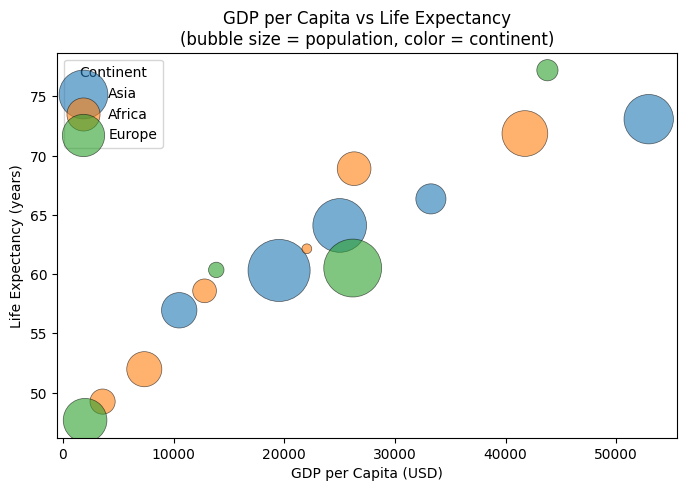

In [ ]:
np.random.seed(1)
n_countries = 15
gdp_per_capita = np.random.uniform(2000, 60000, n_countries)
life_expectancy = 50 + (gdp_per_capita / 60000) * 30 + np.random.normal(0, 3, n_countries)
population = np.random.uniform(1e6, 3e8, n_countries)
continent = np.random.choice(["Asia", "Africa", "Europe"], n_countries)

fig, ax = plt.subplots(figsize=(8, 5))

# CORRECT: scale marker size (area) proportionally to the underlying variable
size_scaled = (population / population.max()) * 2000   # scale into a reasonable point-area range

colors = {"Asia": "tab:blue", "Africa": "tab:orange", "Europe": "tab:green"}
for cont in colors:
    mask = continent == cont
    ax.scatter(
        gdp_per_capita[mask], life_expectancy[mask],
        s=size_scaled[mask], c=colors[cont],
        alpha=0.6, edgecolors="black", linewidths=0.5,
        label=cont,
    )

ax.set_title("GDP per Capita vs Life Expectancy\n(bubble size = population, color = continent)")
ax.set_xlabel("GDP per Capita (USD)")
ax.set_ylabel("Life Expectancy (years)")
ax.legend(title="Continent")
plt.show()


### Parameter Explanation
- `s=size_scaled` — Matplotlib's `s` parameter is in **points²** (area), which is the perceptually correct quantity to scale linearly against your data — do **not** additionally square or manually convert to "radius" before passing it in.
- Normalizing (`population / population.max()`) before scaling into a point-area range keeps bubble sizes in a legible range (too-small bubbles vanish; too-large bubbles overlap and obscure neighbors).

### Common Mistakes
- Manually computing a "radius" from the data and passing `s = radius` (which Matplotlib then treats as area) — this silently distorts the encoding, making differences look smaller than they are.
- Using bubble size for a variable with a huge dynamic range (e.g., population from 1M to 1.4B) without any normalization — the largest bubble dwarfs the chart and tiny ones disappear; consider a `sqrt` or `log` transform of the underlying value before mapping to size in extreme cases.
- Cramming too many dimensions (5+) into one bubble chart — beyond x, y, size, color, most readers can't reliably decode a 5th encoded dimension (e.g., marker shape) simultaneously.

### Best Practices
- Keep bubble size differences to a legible range (~roughly 5x–20x smallest to largest area, not 1000x) — apply a `sqrt`/`log` transform to the underlying variable first if its raw range is extreme.
- Always include a size legend or reference bubbles ("small = 1M, large = 100M") when precision matters — color/position alone is easy to eyeball, but exact bubble *size* comparisons are hard without a reference.

### Interview Insight
**Q: What's the most common mistake when building a bubble chart, and why is it dangerous?**
A: Scaling marker *radius* linearly to the data instead of *area* (`s` in Matplotlib is already an area unit) — since perceived visual magnitude follows area, and area = π·r², a linear-radius scaling causes an unintentional quadratic exaggeration of the true differences in the underlying variable.

### Mini Exercise
Recompute `size_scaled` using a `np.sqrt()` transform of `population` before scaling, and compare how much more legible the smallest bubbles become.

### Quiz (Chapter 14)
1. What unit does Matplotlib's `s` parameter represent?
2. Why does manually computing "radius" and passing it as `s` cause a misleading chart?
3. How many dimensions can a bubble chart reasonably encode before becoming unreadable?


---
# CHAPTER 15 — BAR CHARTS

## 1. Concept
`ax.bar(x, height)` draws vertical rectangles whose **length** encodes magnitude — the standard chart for comparing a quantity **across discrete categories**.

## 2. Why It Matters
Bar charts are the single most common chart in business analytics because category comparison ("which region sold the most?") is one of the most common analytical questions. Their correctness hinges entirely on the zero-baseline rule established in Chapter 10.

## 3–4. NumPy / Pandas Connection
Bar charts are the natural visualization for `df.groupby("category")["value"].sum()` output — the resulting Series' `.index` becomes the x-categories and `.values` becomes the bar heights.

## 5. Industry Use Case
Revenue/sales by region or category, churn rate by segment, model performance comparison across algorithms.


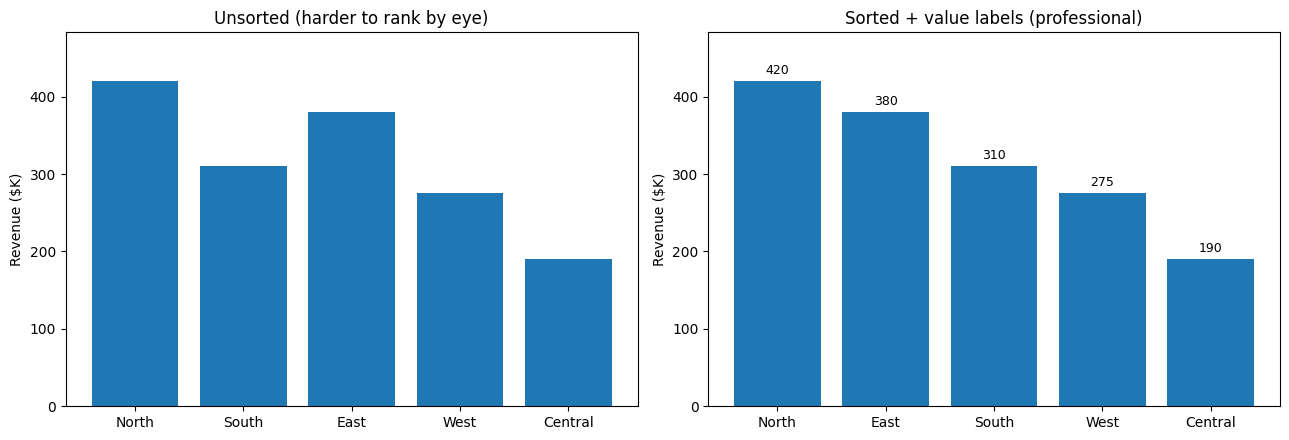

In [ ]:
sales_df = pd.DataFrame({
    "region": ["North", "South", "East", "West", "Central"],
    "revenue": [420, 310, 380, 275, 190],
})
sales_df_sorted = sales_df.sort_values("revenue", ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Vertical bar, unsorted
axes[0].bar(sales_df["region"], sales_df["revenue"], color="tab:blue")
axes[0].set_title("Unsorted (harder to rank by eye)")
axes[0].set_ylabel("Revenue ($K)")

# Vertical bar, sorted descending + value labels — professional pattern
bars = axes[1].bar(sales_df_sorted["region"], sales_df_sorted["revenue"], color="tab:blue")
axes[1].set_title("Sorted + value labels (professional)")
axes[1].set_ylabel("Revenue ($K)")
for bar in bars:
    height = bar.get_height()
    axes[1].annotate(
        f"{height:.0f}",
        xy=(bar.get_x() + bar.get_width() / 2, height),
        xytext=(0, 3), textcoords="offset points",
        ha="center", va="bottom", fontsize=9,
    )

for ax in axes:
    ax.set_ylim(0, sales_df["revenue"].max() * 1.15)

plt.tight_layout()
plt.show()


### Parameter Explanation
| Parameter | Meaning |
|---|---|
| `x` | Category positions (labels or numeric positions) |
| `height` | Bar length — the encoded magnitude |
| `width` | Bar thickness (default `0.8`) |
| `color` / `edgecolor` | Fill and border color |
| `align` | `'center'` (default) or `'edge'` |
| `yerr` | Error bars (Chapter 27) — `ax.bar(x, height, yerr=std_devs, capsize=4)` |

### Internal Working
Each bar is a `Rectangle` Patch Artist; `ax.bar()` returns a `BarContainer` (iterable of these Rectangles), which is exactly what makes the `for bar in bars: ...` value-labeling pattern above possible — you can query `bar.get_height()` / `bar.get_x()` / `bar.get_width()` on every returned Rectangle.

### Interpretation
Sorting bars descending (rather than leaving them in arbitrary/alphabetical order) lets a reader immediately identify the ranking without hunting across the chart — this single change is one of the highest-leverage, lowest-effort improvements to any bar chart.

### Common Mistakes
- **Non-zero y-axis baseline** (see Chapter 10) — the #1 bar chart integrity issue.
- Leaving bars in arbitrary/input order instead of sorted by value when ranking is the point of the chart.
- Using a bar chart for **too many** categories (20+) — switches to unreadable; use a horizontal bar chart (Chapter 16) or aggregate a long tail into "Other."
- Using 3D bar charts — the extra dimension provides no additional information and actively distorts perceived height due to perspective (covered again in Chapter 78's "chart junk" discussion).

### Debugging
If bars appear at unexpected x-positions when mixing numeric and categorical bar calls, check whether `x` was passed as strings vs. numeric positions consistently across multiple `ax.bar()` calls in the same Axes (relevant for grouped bars, Chapter 17).

### Best Practices
- Sort by value when the goal is ranking.
- Start y-axis at zero.
- Add direct value labels on top of bars when precision matters and there are few enough bars for labels not to clutter.
- Use `plt.cm.tab10` or a single consistent brand color rather than a different color per bar with no meaning (color should only vary when it encodes something, e.g., category or a highlighted bar).

### Interview Insight
**Q: You have a bar chart with 25 product categories. What would you change?**
A: Switch to a horizontal bar chart for label readability (Chapter 16), sort by value, and consider grouping the smallest categories into an "Other" bucket if the long tail isn't individually decision-relevant — 25 vertical bars with rotated labels is close to the practical readability ceiling for this chart type.

### Mini Exercise
Recreate the sorted bar chart but highlight the top region by coloring its bar differently (e.g., `"crimson"` for the max, `"tab:blue"` for the rest) using a per-bar color list.

### Coding Challenge
Write a function `plot_ranked_bar(categories, values, ax=None, highlight_top=True)` that: sorts descending, adds value labels, sets a zero-based y-limit with 15% headroom, and optionally colors the top bar differently. Return `(fig, ax)`.


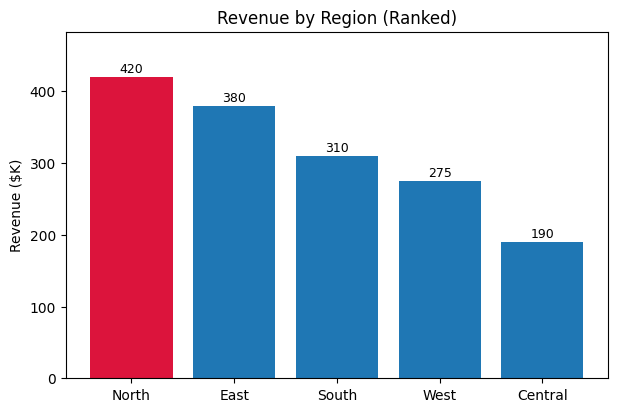

In [ ]:
def plot_ranked_bar(categories, values, ax=None, highlight_top=True):
    order = np.argsort(values)[::-1]
    categories = np.array(categories)[order]
    values = np.array(values)[order]

    if ax is None:
        fig, ax = plt.subplots(figsize=(7, 4.5))
    else:
        fig = ax.get_figure()

    colors = ["crimson" if (i == 0 and highlight_top) else "tab:blue" for i in range(len(values))]
    bars = ax.bar(categories, values, color=colors)

    for bar in bars:
        h = bar.get_height()
        ax.annotate(f"{h:.0f}", xy=(bar.get_x() + bar.get_width() / 2, h),
                    xytext=(0, 3), textcoords="offset points", ha="center", fontsize=9)

    ax.set_ylim(0, values.max() * 1.15)
    return fig, ax

fig, ax = plot_ranked_bar(sales_df["region"], sales_df["revenue"])
ax.set_title("Revenue by Region (Ranked)")
ax.set_ylabel("Revenue ($K)")
plt.show()


### Quiz (Chapter 15)
1. Why must bar chart y-axes start at zero (in almost all cases)?
2. What object does `ax.bar()` return, and how did we use it to add value labels?
3. At roughly what category count should you consider switching from vertical to horizontal bars, or aggregating a long tail?
4. Why are 3D bar charts generally discouraged?

### Chapter 15 Summary
- Bar length = magnitude → zero baseline is mandatory.
- `BarContainer`'s `Rectangle` objects are directly queryable (`get_height()`, `get_x()`, `get_width()`) — the basis for value-label annotation.
- Sort by value whenever ranking is the analytical point of the chart.

---

## END OF NOTEBOOK 2 — What You Should Now Be Able To Do
- Place legends deliberately (including outside the plot) and know when to skip them.
- Choose the correct colormap category (sequential/diverging/qualitative) for a given variable.
- Apply a consistent project-wide style via `rcParams`/`rc_context` instead of manual per-chart styling.
- Combine marker + linestyle for accessible multi-series charts.
- Set axis limits correctly (zero-baseline for bars; deliberate zoom for lines).
- Format ticks professionally (currency, percentages, rotation) without touching underlying data.
- Apply minimalist spine/gridline styling.
- Build correct scatter and bubble charts, avoiding the area-vs-radius pitfall.
- Build ranked, correctly-baselined, value-labeled bar charts, and reuse the pattern as a function.

## Before Moving to Notebook 3 (Chapters 16–25: Horizontal Bars, Grouped Bars, Stacked Bars, Histograms, Histogram Bins, Box Plots, Violin Plots, Pie Charts, Area Plots)
Complete the Mini Exercises, Coding Challenges, and Quizzes above.